# 05 · Missing Data

EM's other life. The same guess-then-fit loop that estimates hidden *labels* also
estimates hidden *missing values*. Treat the blanks as the latent variables:

- **E-step:** fill each hole with its expected value under the current model (for a
  Gaussian, the conditional mean given the observed entries).
- **M-step:** refit the mean and covariance on the completed data.
- Repeat.

This is the principled engine under proper imputation — and, unlike single
mean-filling, it preserves the correlation structure instead of flattening it.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def _repo_root() -> Path:
    here = Path.cwd()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").exists():
            return cand
    return here


ROOT = _repo_root()
FIG_DIR = ROOT / "outputs" / "figures"
DATA_DIR = ROOT / "outputs" / "data"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)


def _jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj


def savefig(fig, name):
    """Save a matplotlib figure as outputs/figures/<name>.png."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"figure -> {path.relative_to(ROOT)}")
    return path


def savejson(name, obj):
    """Save textual/numerical content as outputs/data/<name>.json."""
    path = DATA_DIR / f"{name}.json"
    path.write_text(json.dumps(_jsonable(obj), indent=2))
    print(f"data   -> {path.relative_to(ROOT)}")
    return path


plt.rcParams["figure.figsize"] = (7, 4.2)
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(42)


## A strongly correlated Gaussian, with holes punched in it

In [2]:
from src.datasets.mixtures import make_missing_gaussian

PLANTED = {"mean": [0.0, 0.0], "true_correlation": 0.85, "missing_frac": 0.25,
           "n_samples": 1500, "seed": 11}
true_cov = np.array([[1.0, PLANTED["true_correlation"]], [PLANTED["true_correlation"], 1.0]])

X_full, X_missing, truth = make_missing_gaussian(
    PLANTED["n_samples"], PLANTED["mean"], true_cov,
    missing_frac=PLANTED["missing_frac"], seed=PLANTED["seed"],
)
frac_missing = float(np.isnan(X_missing).mean())
print(f"entries blanked: {frac_missing:.1%}")
savejson("nb05_inputs", {"description": "Correlated 2-D Gaussian with MCAR holes.",
                         "planted_truth": {**PLANTED, "covariance": true_cov},
                         "fraction_missing": frac_missing})


entries blanked: 21.4%
data   -> outputs/data/nb05_inputs.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb05_inputs.json')

## Mean-fill vs EM imputation

In [3]:
from src.em.missing_data import GaussianMissingEM


def corr(cov):
    return float(cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1]))


# EM imputation
em = GaussianMissingEM(random_state=0).fit(X_missing)
corr_em = corr(em.covariance_)

# single mean-fill baseline
observed = ~np.isnan(X_missing)
col_mean = np.nanmean(X_missing, axis=0)
mean_filled = np.where(observed, X_missing, col_mean)
corr_mf = corr(np.cov(mean_filled.T))

print(f"true corr = {PLANTED['true_correlation']:.2f}")
print(f"EM-imputed corr = {corr_em:.3f}")
print(f"mean-fill  corr = {corr_mf:.3f}   (attenuated toward 0)")


true corr = 0.85
EM-imputed corr = 0.864
mean-fill  corr = 0.626   (attenuated toward 0)


## The picture: mean-fill collapses the cloud, EM restores it

Points that were complete are gray. Points that had one coordinate blanked are red — we
plot where each method *placed* them. Mean-fill drops them onto the column-mean lines (a
cross), erasing the correlation; EM places them along the relationship, rebuilding the cloud.


figure -> outputs/figures/nb05_imputation_scatter.png
figure -> outputs/figures/nb05_correlation_bar.png


PosixPath('/workspaces/expectation_maximization_101/outputs/figures/nb05_correlation_bar.png')

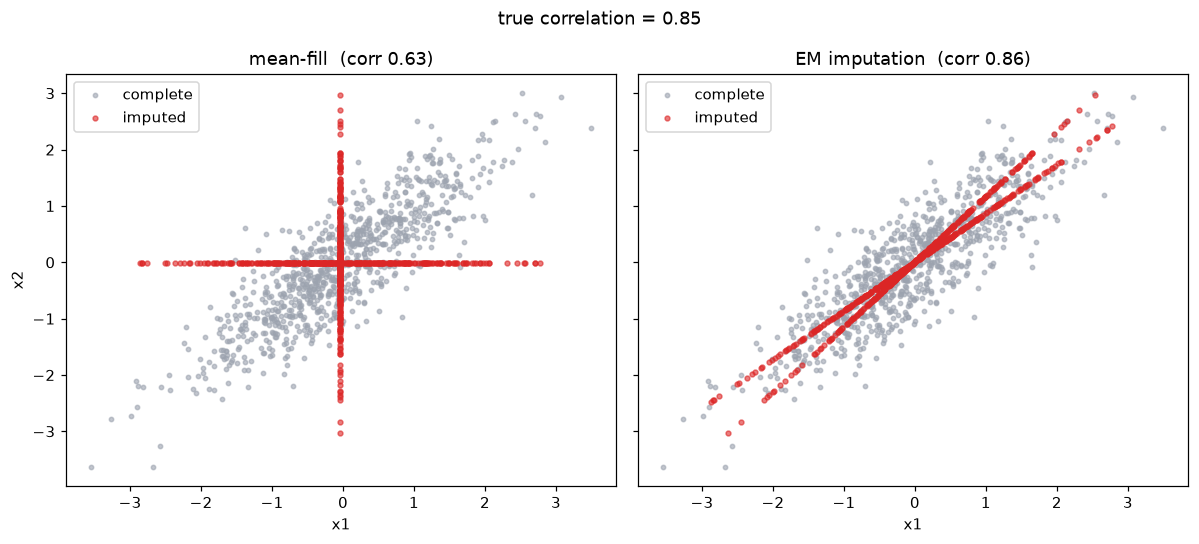

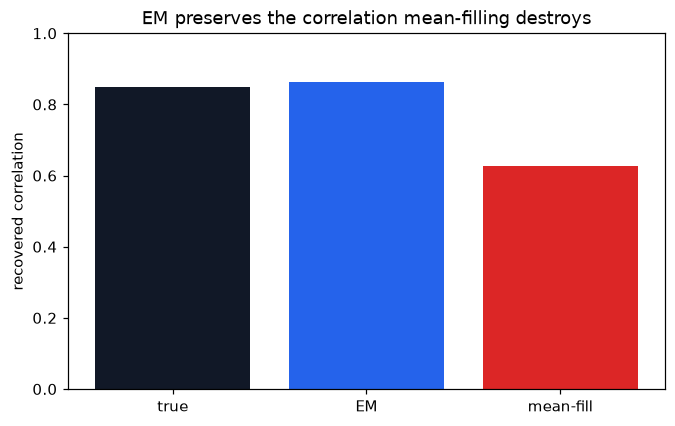

In [4]:
any_missing = ~observed.all(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, data, title in [(axes[0], mean_filled, f"mean-fill  (corr {corr_mf:.2f})"),
                        (axes[1], em.imputed_, f"EM imputation  (corr {corr_em:.2f})")]:
    ax.scatter(data[~any_missing, 0], data[~any_missing, 1], s=8, color="#9ca3af",
               alpha=0.6, label="complete")
    ax.scatter(data[any_missing, 0], data[any_missing, 1], s=10, color="#dc2626",
               alpha=0.6, label="imputed")
    ax.set_title(title); ax.set_xlabel("x1"); ax.legend(loc="upper left")
axes[0].set_ylabel("x2")
fig.suptitle(f"true correlation = {PLANTED['true_correlation']:.2f}")
fig.tight_layout()
savefig(fig, "nb05_imputation_scatter")

fig, ax = plt.subplots()
ax.bar(["true", "EM", "mean-fill"], [PLANTED["true_correlation"], corr_em, corr_mf],
       color=["#111827", "#2563eb", "#dc2626"])
ax.set_ylabel("recovered correlation"); ax.set_ylim(0, 1)
ax.set_title("EM preserves the correlation mean-filling destroys")
savefig(fig, "nb05_correlation_bar")


## Scored against the values that were removed

imputation RMSE   EM=0.523   mean-fill=0.997
figure -> outputs/figures/nb05_loglik.png
data   -> outputs/data/nb05_results.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb05_results.json')

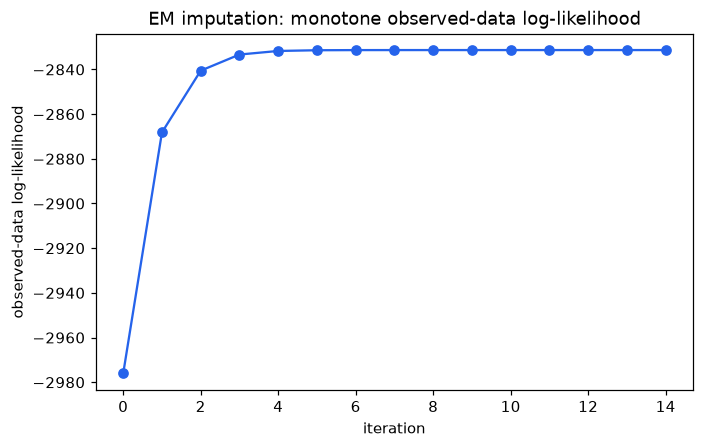

In [5]:
missing_pos = ~observed
truth_vals = X_full[missing_pos]
rmse_em = float(np.sqrt(np.mean((em.imputed_[missing_pos] - truth_vals) ** 2)))
rmse_mf = float(np.sqrt(np.mean((mean_filled[missing_pos] - truth_vals) ** 2)))
print(f"imputation RMSE   EM={rmse_em:.3f}   mean-fill={rmse_mf:.3f}")

assert em.loglik_history_[-1] >= em.loglik_history_[0]  # observed-data log-likelihood climbed
fig, ax = plt.subplots()
ax.plot(em.loglik_history_, marker="o", color="#2563eb")
ax.set_xlabel("iteration"); ax.set_ylabel("observed-data log-likelihood")
ax.set_title("EM imputation: monotone observed-data log-likelihood")
savefig(fig, "nb05_loglik")

savejson("nb05_results", {
    "true_correlation": PLANTED["true_correlation"],
    "correlation_em": corr_em,
    "correlation_meanfill": corr_mf,
    "rmse_em": rmse_em,
    "rmse_meanfill": rmse_mf,
    "recovered_covariance_em": em.covariance_,
    "recovered_mean_em": em.mean_,
    "loglik_history": em.loglik_history_,
})


## Takeaway

Mean-filling makes one non-iterative guess that ignores the model, so it drags every
blanked point to the average and flattens the correlation toward zero. EM fills each hole
with its *model-based* conditional expectation and refits — preserving the structure, and
lowering the imputation error. The clustering algorithm and the imputation algorithm are
the same algorithm, which is why EM is the principled foundation under proper imputation.

**Next:** `06_when_em_struggles` — the honest operator's guide to local optima, model
selection, and failure modes.


In [6]:
savejson("nb05_narrative", {
    "title": "Missing Data",
    "e_step": "Fill each missing entry with its conditional expectation under the current Gaussian.",
    "m_step": "Refit mean and covariance on the completed sufficient statistics.",
    "key_result": "EM preserves correlation and lowers imputation RMSE vs single mean-fill.",
    "figures": {
        "nb05_imputation_scatter": "Mean-fill collapses the cloud; EM restores it.",
        "nb05_correlation_bar": "Recovered correlation: true vs EM vs mean-fill.",
        "nb05_loglik": "Monotone observed-data log-likelihood.",
    },
})


data   -> outputs/data/nb05_narrative.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb05_narrative.json')